# MayaCardio Signal-Processing Assessment — PPG Case

**Goal:** inspect raw PPG recordings, verify packet integrity, formulate hypotheses, test one mitigation, and document limitations.

**Before submission:** run every cell from top to bottom, inspect the plots, and rewrite the interpretation in your own words. The assessment explicitly says you may use AI, but you must disclose where it helped and be able to explain/adapt your work in the interview.

**Expected input file:** `MayaCardio_Signal_Processing_Case_Data_ppg.json` in the same folder as this notebook.

In [1]:
# If a package is missing, run this once in a notebook cell:
# %pip install numpy scipy matplotlib pandas

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, find_peaks, iirnotch, filtfilt, butter, sosfiltfilt

FS = 200.0
DATA_FILE = Path("../data/MayaCardio_Signal_Processing_Case_Data_ppg.json")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE.name}. Put it in the same folder as this notebook "
        "or update DATA_FILE to its full path."
    )

raw = json.loads(DATA_FILE.read_text(encoding="utf-8"))
assert raw["sampling_rate_hz"] == FS
print("Recordings:", len(raw["recordings"]), "| sampling rate:", FS, "Hz")
print("Expected samples per recording:", raw["expected_samples_per_recording"])

Recordings: 5 | sampling rate: 200.0 Hz
Expected samples per recording: 6000


In [3]:
# Reconstruct by explicit sample index, not by assuming packet order is perfect.
signals = {}
packet_audit = []
for rec in raw["recordings"]:
    rid = rec["recording_id"]
    x = np.full(raw["expected_samples_per_recording"], np.nan, dtype=float)
    occupied = np.zeros(len(x), dtype=bool)
    packet_rows = []
    for pkt in rec["packets"]:
        start = int(pkt["first_sample_index"])
        values = np.asarray(pkt["values"], dtype=float)
        end = start + len(values)
        if start < 0 or end > len(x):
            raise ValueError(f"{rid}: packet {pkt['sequence']} has invalid sample range")
        if occupied[start:end].any():
            raise ValueError(f"{rid}: overlapping packet samples near index {start}")
        x[start:end] = values
        occupied[start:end] = True
        packet_rows.append((pkt["sequence"], start, len(values), pkt["nominal_first_sample_time_s"]))
    missing = np.flatnonzero(~occupied)
    signals[rid] = x
    packet_audit.append({
        "recording": rid,
        "packets_received": len(rec["packets"]),
        "samples_present": int(occupied.sum()),
        "samples_missing": int((~occupied).sum()),
        "missing_intervals_s": (
            "none" if len(missing) == 0 else
            "; ".join(f"{a/FS:.3f}-{(b+1)/FS:.3f}s" for a,b in
                      zip(missing[np.r_[True, np.diff(missing)>1]],
                          missing[np.r_[np.diff(missing)>1, True]]))
        )
    })
audit = pd.DataFrame(packet_audit)
display(audit)


,recording,packets_received,samples_present,samples_missing,missing_intervals_s
0,S1,60,6000,0,none
1,S2,60,6000,0,none
2,S3,60,6000,0,none
3,S4,60,6000,0,none
4,S5,58,5800,200,10.000-11.000s


## 1. Raw waveforms (do not filter first)

Missing samples are deliberately left as gaps (`NaN`) so the plot does not falsely draw a continuous line through absent data.

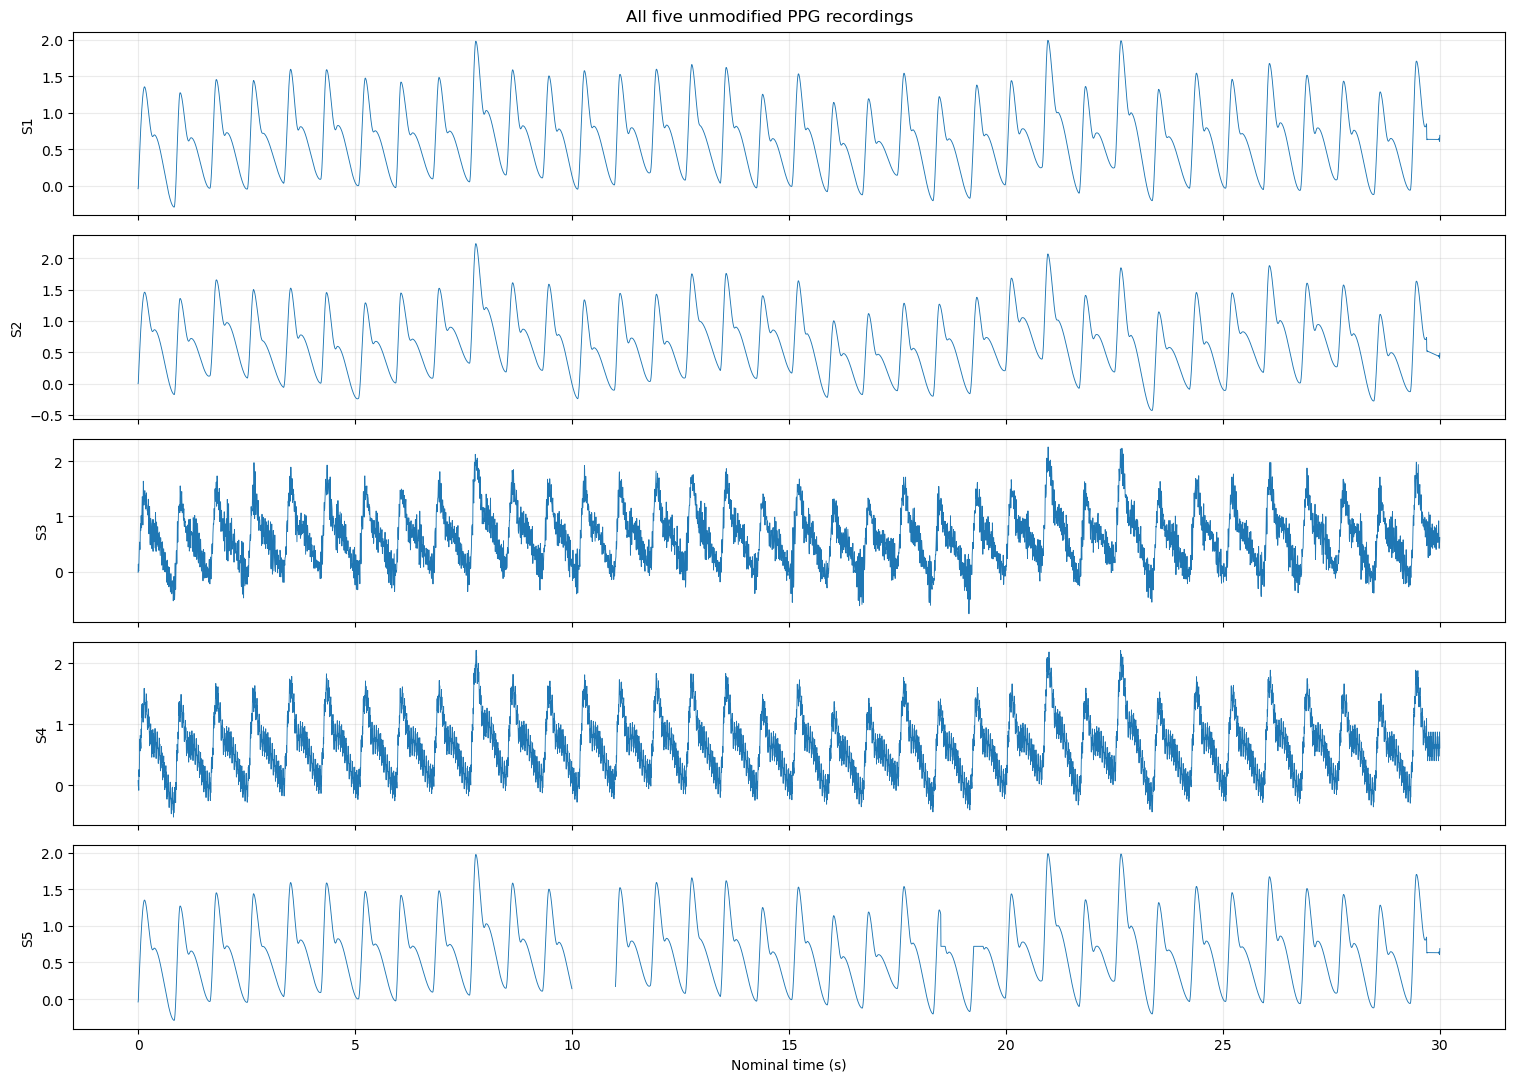

In [4]:
t = np.arange(raw["expected_samples_per_recording"]) / FS
fig, axes = plt.subplots(5, 1, figsize=(15, 11), sharex=True)
for ax, (rid, x) in zip(axes, signals.items()):
    ax.plot(t, x, lw=0.65)
    ax.set_ylabel(rid)
    ax.grid(True, alpha=0.25)
axes[-1].set_xlabel("Nominal time (s)")
fig.suptitle("All five unmodified PPG recordings")
fig.tight_layout()
plt.savefig("../outputs/plots/raw_waveforms.png",
            dpi=200, bbox_inches="tight")
plt.show()

## Preliminary observations of raw PPG recordings

- **S1:** Individual pulses are recognizable, with occasional unusually high peaks. Their cause is uncertain.
- **S2:** Pulses remain recognizable, with variation in amplitude and baseline level. Baseline drift requires further verification.
- **S3:** Rapid fluctuations are superimposed on the pulse waveform, suggesting a stronger noise component.
- **S4:** A rapid ripple is visible while individual pulses remain recognizable. Frequency analysis is needed to investigate the disturbance.
- **S5:** The packet audit identified 200 missing samples from 10 to 11 seconds. Continuous pulse measurement across this interval is unreliable.

These observations are provisional. Frequency analysis and targeted tests are needed before assigning physical causes or claiming that processing improves measurement quality.

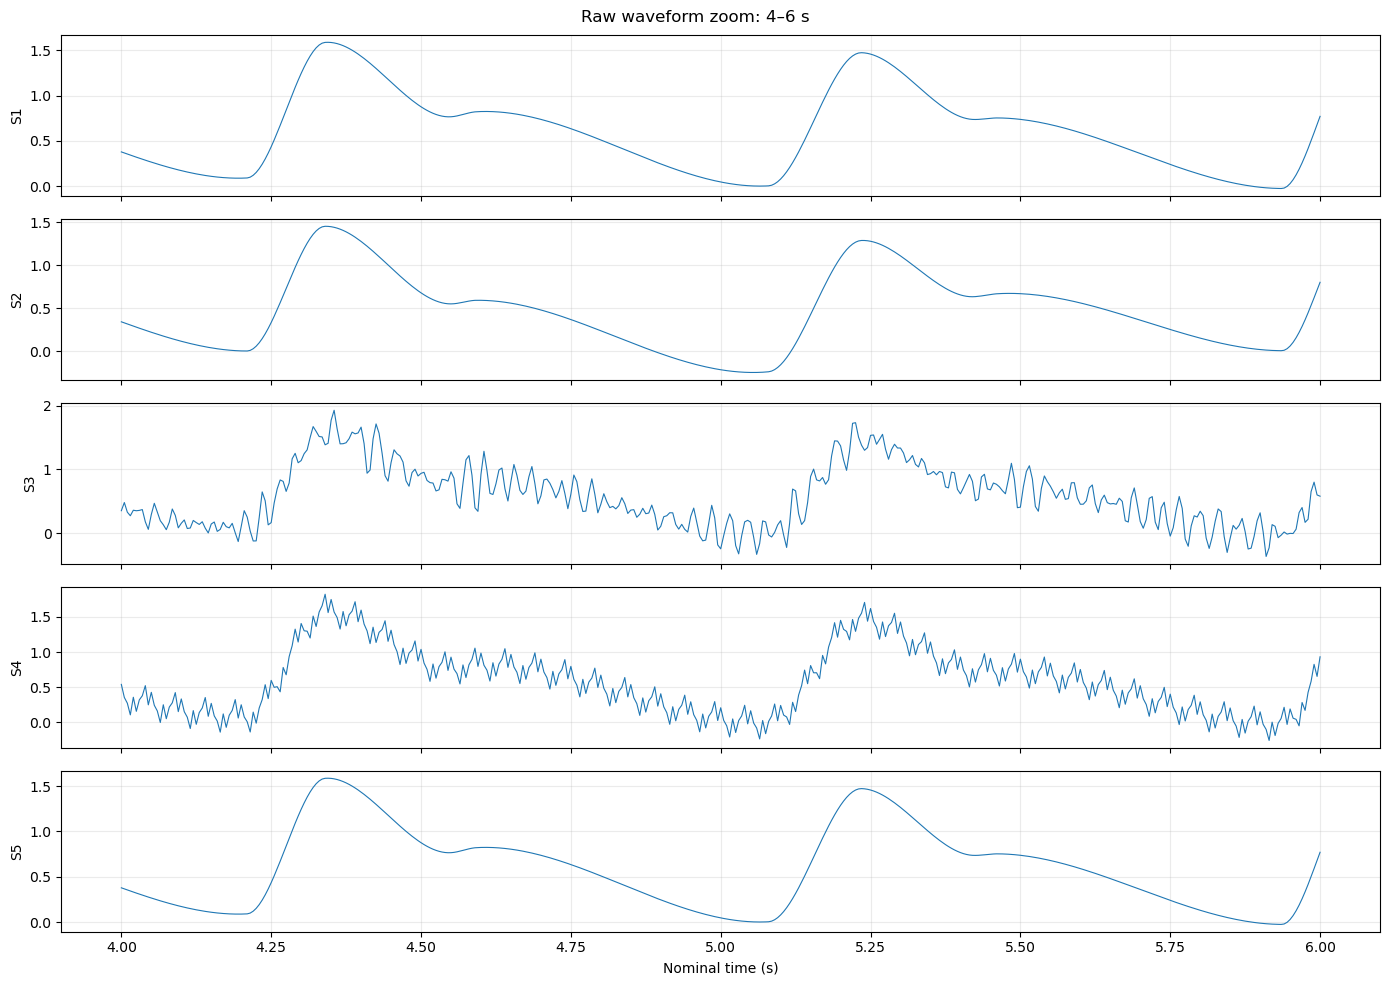

In [5]:
# Zoom into a representative 2-second interval for detailed morphology comparison.
start_s, end_s = 4.0, 6.0
fig, axes = plt.subplots(5, 1, figsize=(14, 10), sharex=True)
for ax, (rid, x) in zip(axes, signals.items()):
    m = (t >= start_s) & (t <= end_s)
    ax.plot(t[m], x[m], lw=0.8)
    ax.set_ylabel(rid)
    ax.grid(True, alpha=0.25)
axes[-1].set_xlabel("Nominal time (s)")
fig.suptitle(f"Raw waveform zoom: {start_s:g}–{end_s:g} s")
fig.tight_layout()
plt.show()

## 2. Frequency-domain inspection

Welch PSD is an exploratory diagnostic. For S5, this cell uses only contiguous observed samples concatenated together; that can distort frequency interpretation around the gap. Treat S5's spectrum as provisional and rely on the packet audit for the missing-data finding.

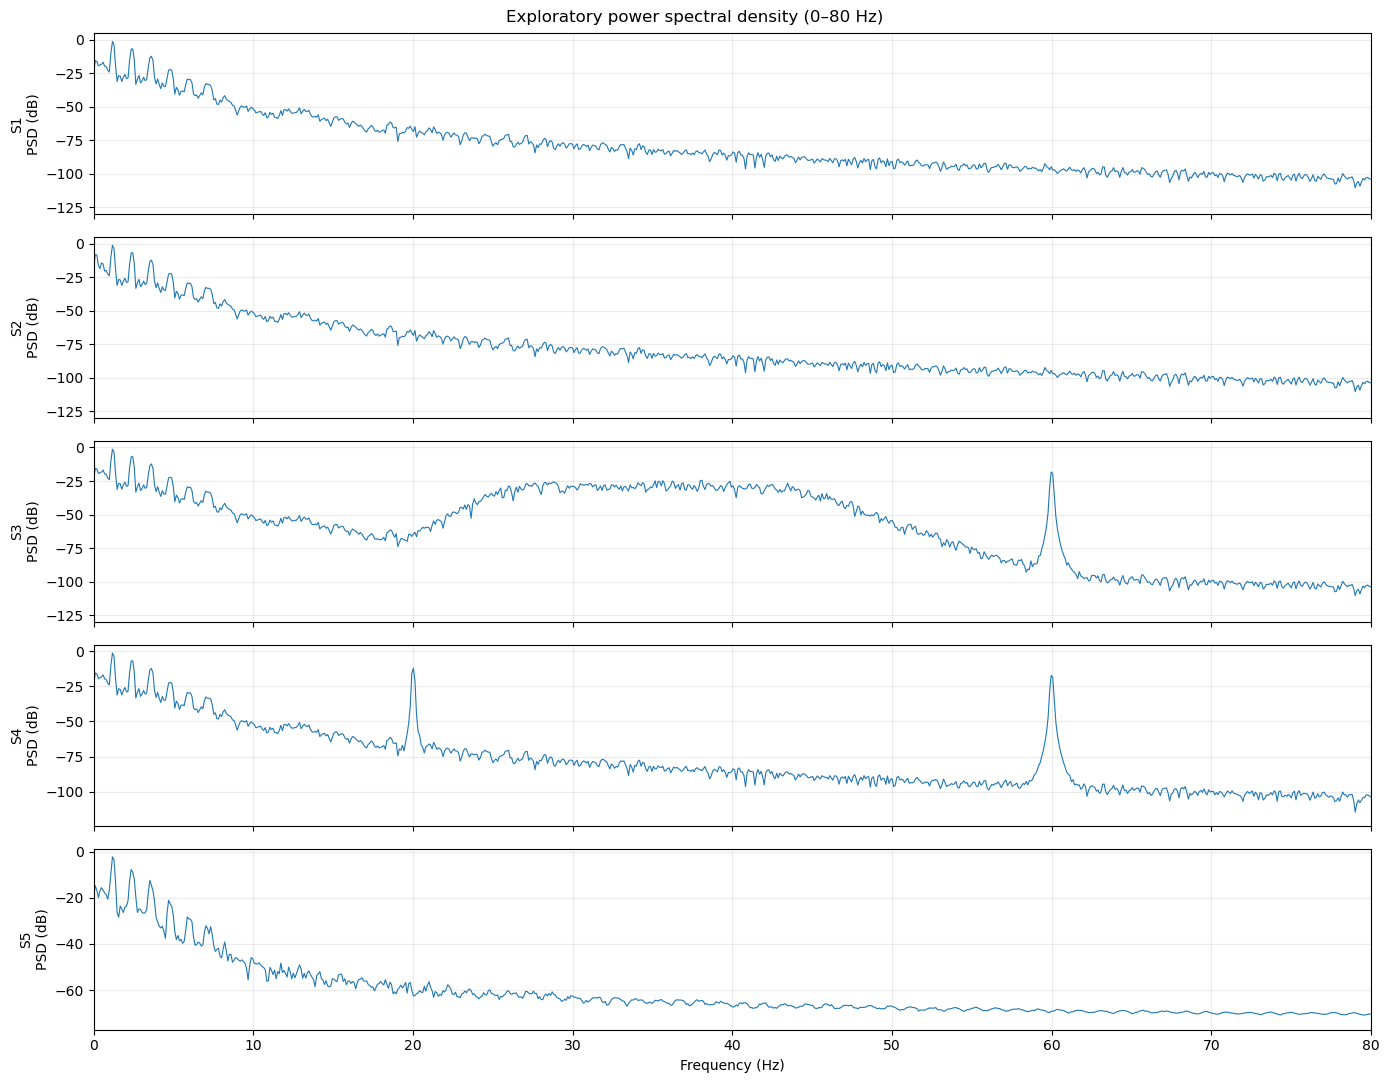

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for ax, (rid, x) in zip(axes, signals.items()):
    valid = np.isfinite(x)
    xv = x[valid]
    f, pxx = welch(xv, fs=FS, nperseg=min(2048, len(xv)))
    ax.plot(f, 10*np.log10(pxx + 1e-15), lw=0.8)
    ax.set_ylabel(f"{rid}\nPSD (dB)")
    ax.grid(True, alpha=0.25)
    ax.set_xlim(0, 80)
axes[-1].set_xlabel("Frequency (Hz)")
fig.suptitle("Exploratory power spectral density (0–80 Hz)")
fig.tight_layout()
plt.savefig("../outputs/plots/power_spectra.png",
            dpi=200, bbox_inches="tight")
plt.show()

## Frequency-Domain Observations

- **S1:** The PSD generally decreases with frequency, with no narrow peak as prominent as those observed in S3 and S4. S1 is a comparison stream, not a verified clean reference.
- **S2:** The overall PSD shape is broadly similar to S1. A full-recording PSD alone cannot establish whether baseline drift occurs.
- **S3:** Elevated spectral energy is visible over approximately 20–50 Hz, with a prominent narrow peak near 60 Hz. Broadband noise and periodic interference are possible explanations, but their physical sources remain unconfirmed.
- **S4:** Prominent narrow peaks appear near 20 Hz and 60 Hz. These components should be investigated as possible periodic disturbances before choosing a mitigation method.
- **S5:** The PSD was calculated from observed samples after omitting missing samples. The one-second gap limits interpretation, and the result should be treated as exploratory.

### Preliminary conclusion

S3 and S4 merit further investigation because of their distinctive spectral features. S4 is a candidate for a targeted 20 Hz notch-filter experiment. The filter must be evaluated using the same pulse interval before and after processing, including timing and morphology measurements. Spectral peaks alone do not prove that a component is unwanted or identify its physical source.

## 3. Mitigation experiment: test a 20 Hz notch on S4

**Hypothesis:** S4 contains a narrow periodic high-frequency component near 20 Hz. A notch filter may reduce that component while preserving the slower pulse waveform.

**Important:** a filter is not automatically an improvement. Compare the same time interval and the same pulse; check timing, height, width and area. A notch may still alter pulse shape, so do not claim clinical validity based on a prettier plot.

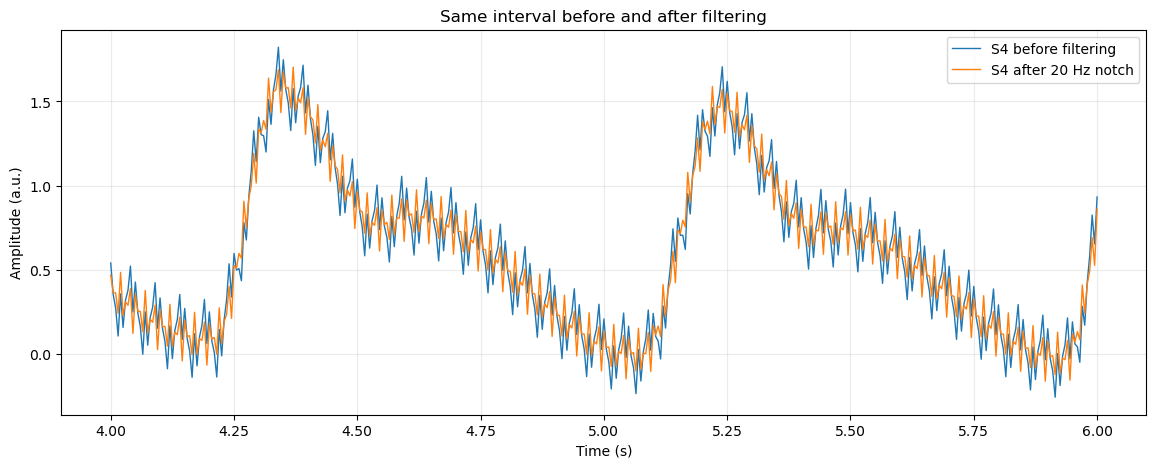

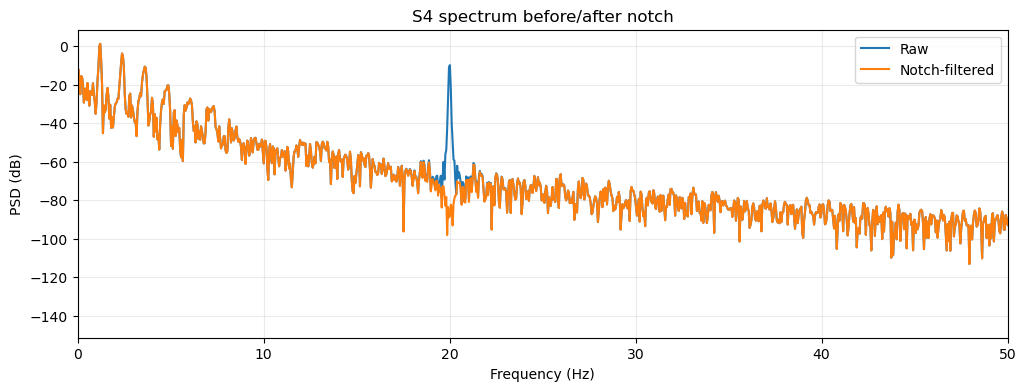

In [7]:
# 20 Hz notch filter, Q=25. Apply zero-phase filtering offline to avoid phase delay.
rid = "S4"
x = signals[rid].copy()
if not np.isfinite(x).all():
    raise ValueError(f"{rid} contains missing or non-finite samples; handle gaps before filtering.")
f0, Q = 20.0, 25.0
b, a = iirnotch(w0=f0, Q=Q, fs=FS)
y = filtfilt(b, a, x)

lo, hi = 4.0, 6.0
m = (t >= lo) & (t <= hi)
fig, ax = plt.subplots(figsize=(14, 5))

# Waveform comparison: before and after filtering
ax.plot(t[m], x[m], label="S4 before filtering", lw=1.0)
ax.plot(t[m], y[m], label="S4 after 20 Hz notch", lw=1.0)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (a.u.)")
ax.set_title("Same interval before and after filtering")
ax.grid(True, alpha=0.25)
ax.legend()

plt.savefig("../outputs/plots/s4_before_after.png",
            dpi=200, bbox_inches="tight")
plt.show()

# PSD before/after over the full recording
f1, p1 = welch(x, fs=FS, nperseg=4096)
f2, p2 = welch(y, fs=FS, nperseg=4096)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(f1, 10*np.log10(p1 + 1e-15), label="Raw")
ax.plot(f2, 10*np.log10(p2 + 1e-15), label="Notch-filtered")
ax.set_xlim(0, 50)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (dB)")
ax.grid(True, alpha=0.25)
ax.legend()
ax.set_title("S4 spectrum before/after notch")

plt.savefig("../outputs/plots/s4_filter_spectrum.png",
            dpi=200, bbox_inches="tight")
plt.show()

### Interpretation of S4 Notch Filtering Results

The raw S4 power spectral density contains a prominent narrowband component near 20 Hz. After applying a 20 Hz notch filter with \(Q=25\), this peak is substantially attenuated, while much of the remaining spectrum is preserved.

The time-domain comparison shows that the principal waveform morphology is visually similar before and after filtering. This suggests that the filter targets the narrowband component without visibly changing the major waveform features in the displayed interval.

However, visual inspection alone is insufficient to establish overall signal-quality improvement. Further validation should quantify attenuation near 20 Hz, assess preservation of useful PPG features, and compare peak-detection performance using appropriately matched peaks. The physical source of the 20 Hz component cannot be determined from these plots alone.

In [8]:
# Compare pulse descriptors for corresponding pulse peaks in the same interval.
# This is a simple exploratory detector, not a validated PPG algorithm.
# Use a minimum peak spacing of 0.35 s (max plausible detector rate ~171 bpm).
seg_idx = np.flatnonzero(m)
xs, ys, ts = x[seg_idx], y[seg_idx], t[seg_idx]
distance = int(0.35 * FS)
peaks_raw, _ = find_peaks(xs, distance=distance, prominence=0.15)
peaks_filt, _ = find_peaks(ys, distance=distance, prominence=0.15)

def descriptors(sig, peaks, time_axis, fs):
    rows = []
    for k, p in enumerate(peaks):
        # local baseline: minimum in a 0.35 s window before the peak
        left = max(0, p-int(0.35*fs))
        baseline = np.min(sig[left:p+1]) if p > left else sig[p]
        height = sig[p] - baseline
        # width at half prominence is an approximate width descriptor
        rows.append({"peak_time_s": time_axis[p], "peak_amp_au": sig[p],
                     "local_height_au": height})
    return pd.DataFrame(rows)

raw_desc = descriptors(xs, peaks_raw, ts, FS)
filt_desc = descriptors(ys, peaks_filt, ts, FS)
print("Raw detected peaks")
display(raw_desc)
print("Filtered detected peaks")
display(filt_desc)
print("Caution: detections are not guaranteed to be one-to-one. Manually confirm that the same pulse is matched.")


Raw detected peaks


,peak_time_s,peak_amp_au,local_height_au
0,4.34,1.822345,1.960670
1,4.69,0.989555,0.442451
2,5.24,1.706241,1.941074
3,5.59,0.845986,0.426036
4,5.99,0.825803,1.082115


Filtered detected peaks


,peak_time_s,peak_amp_au,local_height_au
0,4.02,0.484900,0.243600
1,4.37,1.703961,1.769308
2,4.72,0.852611,0.259941
3,5.22,1.589710,1.736803
4,5.57,0.799938,0.265770
5,5.99,0.692125,0.853154


Caution: detections are not guaranteed to be one-to-one. Manually confirm that the same pulse is matched.


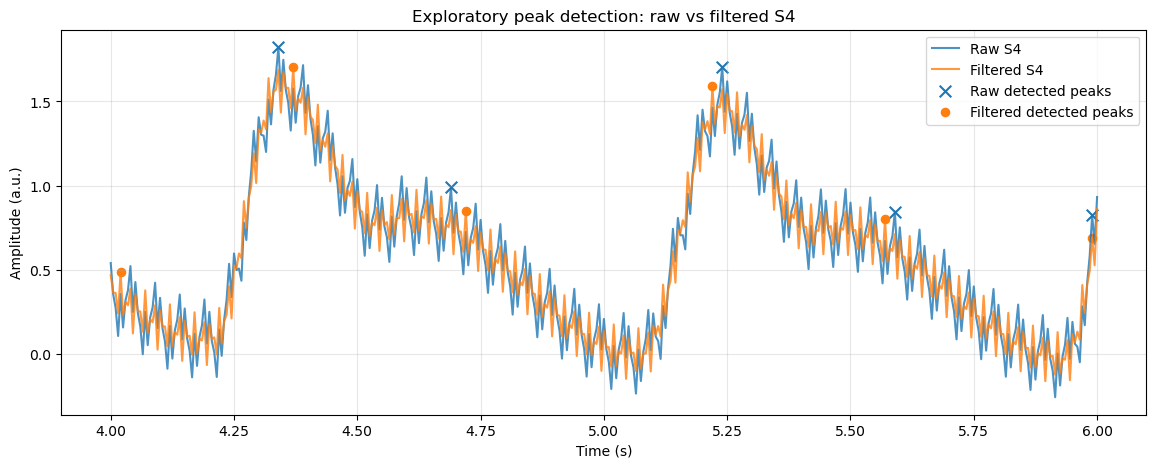

Raw peak times: [4.34 4.69 5.24 5.59 5.99]
Filtered peak times: [4.02 4.37 4.72 5.22 5.57 5.99]


In [9]:
# Compare peak locations on the same 4–6 second interval
# using a lower prominence threshold for exploratory inspection.

from scipy.signal import find_peaks
import matplotlib.pyplot as plt

distance = int(0.35 * FS)
prominence = 0.10

peaks_raw2, _ = find_peaks(
    xs, distance=distance, prominence=prominence
)

peaks_filt2, _ = find_peaks(
    ys, distance=distance, prominence=prominence
)

plt.figure(figsize=(14, 5))
plt.plot(ts, xs, label="Raw S4", alpha=0.8)
plt.plot(ts, ys, label="Filtered S4", alpha=0.8)

plt.scatter(
    ts[peaks_raw2], xs[peaks_raw2],
    marker="x", s=70, label="Raw detected peaks"
)
plt.scatter(
    ts[peaks_filt2], ys[peaks_filt2],
    marker="o", s=35, label="Filtered detected peaks"
)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.title("Exploratory peak detection: raw vs filtered S4")
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig("../outputs/plots/s4_peak_detection.png",
            dpi=200, bbox_inches="tight")
plt.show()

print("Raw peak times:", np.round(ts[peaks_raw2], 3))
print("Filtered peak times:", np.round(ts[peaks_filt2], 3))

### Peak Detection and Filtering Validation

The raw and notch-filtered S4 signals retain broadly similar waveform morphology. However, the exploratory peak detector produces different detection lists. The raw signal contains five detected peaks, whereas the filtered signal contains six.

The nearest prominent peak matches show timing differences of approximately +30 ms, +30 ms, −20 ms, −20 ms and approximately 0 ms. These differences should not be interpreted as definitive timing shifts because the detector may identify secondary waveform features, and correspondence has not been independently validated.

The filter suppresses the narrow spectral component near 20 Hz, but the current experiment does not establish that pulse measurement quality has improved. Further work should use a validated pulse-matching procedure, consistent baseline definitions and quantitative morphology comparisons. The additional detection should be investigated rather than automatically classified as a real pulse.

# Q1A — Raw PPG Observations, Hypotheses and Quality Decisions

## 1. Observations across the five streams

### S1 — Pulse morphology and amplitude excursions
The raw waveform contains recognizable pulse-like cycles. Some peaks reach unusually high amplitudes, including visible excursions around 7–8 seconds and approximately 21–23 seconds. These could represent genuine pulse variation or measurement artifacts. The available waveform alone does not establish the cause.

**Decision:** Review the unusual intervals before accepting amplitude-dependent measurements. Other intervals may remain usable after appropriate checks.

### S2 — Pulse and baseline variation
S2 retains recognizable pulse morphology and has a broadly similar power spectral density to S1. Its amplitude and baseline vary over time. A full-recording PSD cannot establish whether this variation is baseline drift; a local baseline analysis is needed.

**Decision:** Review intervals where baseline variation affects pulse detection or amplitude measurement.

### S3 — Broadband energy and narrowband disturbance
S3 appears rougher than S1 and S2 in the time domain. Its PSD shows elevated energy over approximately 20–50 Hz and a prominent narrow peak near 60 Hz. These features are consistent with broadband noise and a periodic component, respectively, but do not prove their physical sources.

**Decision:** Review the affected intervals and quantify the effect on pulse detection before accepting measurements.

### S4 — Periodic spectral components
S4 contains recognizable pulse-like cycles with rapid fluctuations superimposed on the waveform. Its PSD has prominent narrow peaks near 20 Hz and 60 Hz. These are candidates for periodic disturbances that warrant further investigation.

**Decision:** Review the recording and evaluate targeted mitigation while checking whether pulse timing and morphology remain reliable.

### S5 — Missing samples
The packet-integrity audit found 58 packets and 5,800 observed samples, compared with the expected 60 packets and 6,000 samples. The missing 200 samples correspond to the interval from 10 to 11 seconds at a sampling frequency of 200 Hz.

**Decision:** Reject the affected interval for measurements that require continuous data. Preserve the gap explicitly. Other intervals can be evaluated separately.

## 2. Competing hypotheses for S4

**Observation:** S4 contains rapid waveform fluctuations and a prominent spectral peak near 20 Hz.

**Hypothesis 1 — Periodic electrical or acquisition interference**

Prediction: The narrow spectral component may persist under controlled conditions even when the physical measurement conditions change.

Discriminating test: Inspect raw ADC samples and analog front-end output, and repeat the measurement with a controlled input or appropriate electronics-only test.

**Hypothesis 2 — A genuine signal component or measurement-related artifact**

Prediction: The component may change when the sensor, contact conditions or physical measurement conditions change.

Discriminating test: Repeat controlled measurements while changing one factor at a time and compare the component against a reference measurement where available.

Neither hypothesis is established by the supplied waveform alone.

## 3. Overall conclusion

The five recordings exhibit different data-quality characteristics. S3 and S4 require investigation of their distinctive spectral features, while S5 has a verified one-second missing-data interval. The available evidence supports interval-specific quality decisions, not a diagnosis of the sensor or acquisition hardware. Further controlled tests are needed to establish physical causes.

# Q1B — Filtering Experiment and Validation

## Method
A digital IIR notch filter with a centre frequency of 20 Hz and quality factor Q = 25 was applied to S4 using forward-backward filtering with SciPy's filtfilt function. The filtered waveform and power spectrum were compared with the raw signal. The waveform comparison used the same 4–6 second interval.

## Observed result
The PSD shows substantial suppression of the narrow component near 20 Hz. The filtered waveform retains broadly recognizable pulse morphology, but visible fluctuations remain. The component near 60 Hz is not the target of this notch filter.

## Measurement validation
The initial peak detector returned five raw detections and six filtered detections in the selected interval. The lists are not guaranteed to correspond one-to-one, so this difference cannot be interpreted as a confirmed change in heartbeat count. Nearest prominent detections differ by approximately 20–30 ms for some peaks, but these are preliminary comparisons rather than validated filter-induced timing shifts.

## Limitations and next steps
The experiment demonstrates targeted spectral suppression, but it does not yet prove an improvement in pulse-measurement quality. The next step is to match the same physical pulses, use consistent baseline and width definitions, and compare peak timing, height, width and area. A filter that reduces noise but damages useful waveform information must not be described as successful without qualification.

The use of filtfilt is suitable for this offline experiment. A real-time implementation would require a causal filtering approach and separate evaluation of latency, phase response and stability.

# Q1C — Sampling, Aliasing and Anti-Aliasing

The sampling frequency is 200 Hz, giving a Nyquist frequency of 100 Hz. Frequencies above the Nyquist limit can alias into lower frequencies during sampling if the analog input is not appropriately band-limited.

The hypothetical useful signal extends to 30 Hz. The disturbance at 10 Hz and motion components between 0.5 and 2 Hz overlap the useful signal band. Therefore, a digital filter cannot remove these components cleanly without potentially removing useful information.

An analog anti-aliasing low-pass filter should be applied before the ADC to attenuate out-of-band components before sampling. Once aliasing has occurred, the original out-of-band frequency generally cannot be recovered uniquely from the sampled data.

A 10 Hz notch filter may be considered only if the component is known to be unwanted and the useful signal around 10 Hz is not required. Motion artifacts may require improved sensor contact, motion control or reference sensing rather than digital filtering alone.

The cutoff frequency and filter order must be selected based on the useful signal bandwidth, acceptable attenuation and ADC requirements. A nominal cutoff of 30 Hz is not sufficient by itself to establish an adequate anti-aliasing design.

## Case 2 — Whole-Chain Fault Tracing

### Objective

Identify possible causes of poor PPG signal quality across the complete acquisition and processing chain, from the sensor and analogue front end to sampling, data transmission, digital filtering, and downstream interpretation.

### 1. Observed Issue: Narrowband Interference in S4

**Evidence:** The S4 power spectrum contains a prominent narrow peak near 20 Hz. The applied 20 Hz notch filter substantially attenuates this component.

**Possible fault locations:**
- Sensor or analogue front-end circuitry.
- Power-supply coupling, grounding, wiring, or electromagnetic interference.
- Digital processing or other periodic interference introduced during acquisition.

**Diagnostic approach:**
- Compare the spectral peak across channels and recording sessions.
- Inspect the acquisition hardware, wiring, grounding, and power supply.
- Check whether the component is stable in frequency and amplitude.
- Compare raw and filtered spectra to quantify attenuation near 20 Hz.

**Recommended action:** Investigate the physical source before relying on filtering as a permanent solution. Retain the notch filter only if validation confirms that it reduces the unwanted component without unacceptable distortion of useful PPG features.

### 2. Observed Issue: Missing Samples in S5

**Evidence:** At a sampling rate of 200 Hz, a 30-second recording should contain 6,000 samples. The observed recording contains 5,800 samples, indicating 200 missing samples, corresponding to approximately one second of data.

**Possible fault locations:**
- Lost or dropped data packets.
- Buffer overflow or acquisition interruptions.
- Incorrect timestamp handling or sample-count accounting.
- Data ingestion or file-processing errors.

**Diagnostic approach:**
- Compare expected and observed sample counts.
- Inspect packet sequence numbers and timestamps, if available.
- Identify the start and end of the missing interval.
- Determine whether the gap occurs in one channel or across multiple channels.

**Recommended action:** Preserve timestamps and explicitly flag missing intervals. Investigate the acquisition and transmission pipeline rather than silently joining samples across gaps. Do not reconstruct missing data without documenting and validating the method.

### 3. Observed Issue: Unusual Amplitude and Baseline Variation

**Evidence:** The initial signal inspection indicates occasional unusually high peaks in S1 and amplitude or baseline variation in S2.

**Possible fault locations:**
- Motion artefacts or changing sensor contact.
- Sensor placement or pressure variations.
- Baseline drift or analogue front-end saturation.
- Transient electrical interference.

**Diagnostic approach:**
- Inspect the affected time intervals in the raw waveform.
- Check for clipping, abrupt discontinuities, and baseline drift.
- Compare the affected channels with other channels and available acquisition metadata.
- Evaluate signal-quality indicators before downstream peak detection.

**Recommended action:** Flag suspicious segments and investigate sensor contact and acquisition conditions. Apply baseline correction or artefact-handling methods only when justified by the observed problem and validated against the useful signal.

### 4. End-to-End Validation Plan

The complete signal-processing chain should be tested using repeatable inputs and explicit acceptance criteria.

| Test | Expected verification |
|---|---|
| Controlled 20 Hz interference | Detect the narrowband component and quantify its attenuation after filtering. |
| Deliberately introduced sample gap | Detect and report the missing interval and its duration. |
| Artificial amplitude artefact | Flag the affected segment without silently altering the original data. |
| Raw-versus-filtered comparison | Check interference reduction and preservation of useful waveform morphology. |
| Peak-detection comparison | Match corresponding peaks and evaluate timing differences, missed detections, and extra detections. |

Acceptance thresholds should be defined before testing and should reflect the intended application. Results should be reproducible across repeated trials and representative signal conditions.

### Conclusion

The observed data indicate multiple signal-quality concerns: narrowband interference in S4, missing samples in S5, and amplitude or baseline variations in other channels. These observations identify where further diagnosis is needed, but they do not independently establish the underlying physical causes.

A reliable system should combine acquisition diagnostics, sample-integrity checks, signal-quality monitoring, carefully validated filtering, and transparent reporting of uncertain or unusable segments. Filtering alone cannot correct missing data or guarantee reliable physiological measurements.

## Judgment Situations

### Situation A — Should Low-Quality Signal Segments Be Removed?

**Judgment:** Do not automatically delete or silently discard low-quality signal segments. Flag them and preserve the original data for traceability.

**Reasoning:** Removing data without recording the reason can hide acquisition problems and bias downstream analysis. Quality flags allow downstream processing to distinguish reliable segments from questionable ones.

**Action:** Record the affected channel, timestamps, quality issue, and reason for exclusion. Exclude segments from specific measurements only when justified by a defined quality criterion, and report the exclusions.

### Situation B — Can We Claim That Filtering Improved the Signal?

**Judgment:** Not until the improvement has been demonstrated using appropriate validation.

**Reasoning:** A filter can reduce unwanted frequency components but may also distort useful signal features. A change in peak count or peak timing alone does not establish overall improvement.

**Action:** Compare the original and filtered signals using the same complete time intervals. Evaluate interference attenuation, preservation of useful PPG morphology, and consistency of detected peaks. Report the metrics and limitations, and qualify or withdraw any improvement claim that the evidence does not support.

## AI and Tool Usage Disclosure

### Tools Used

- **Python:** Data processing and numerical analysis.
- **NumPy and pandas:** Numerical operations and data handling.
- **SciPy:** Signal filtering, frequency analysis, and related signal-processing operations.
- **Matplotlib:** Signal and frequency-domain visualizations.
- **Jupyter Notebook:** Execution, analysis, and documentation.
- **AI assistance:** Used to support code review, explanation of signal-processing concepts, and organization of technical findings.

### Verification and Limitations

The analysis is based on the supplied dataset and the results produced by the notebook. The code and outputs should be reviewed and rerun before submission to verify reproducibility.

The observed spectral peaks and missing-sample interval are evidence of signal-quality issues, but they do not independently establish their physical causes. Recommendations and conclusions are therefore limited to what the available data support. Any claims about filtering effectiveness require appropriate validation.